In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
cols = ["area" , "perimeter" , "compactness" , "length" , "width" , "asymmetry" , "groove", "class"]
df = pd.read_csv("seeds_dataset.txt" , names=cols , sep="\s+")

<>:2: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:2: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
/var/folders/lg/sczlvrbj0p160b6h4_hgrr2r0000gn/T/ipykernel_6635/2697875850.py:2: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  df = pd.read_csv("seeds_dataset.txt" , names=cols , sep="\s+")


In [3]:
df.head()

,area,perimeter,compactness,length,width,asymmetry,groove,class
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


In [ ]:
for i in range(len(cols)-1):
    for j in range(i+1, len(cols)-1):
        x_label = cols[i]
        y_label = cols[j]
        sns.scatterplot(x=x_label, y=y_label, data=df, hue='class')
        plt.show()

## Clustering

In [5]:
from sklearn.cluster import KMeans

In [6]:
x= "perimeter"
y= "asymmetry"
x= df[[x,y]].values

In [7]:
KMeans = KMeans(n_clusters=3).fit(x)

In [8]:
clusters = KMeans.labels_

In [9]:
clusters_df = pd.DataFrame(
    np.hstack((x, clusters.reshape(-1, 1))), 
    columns=["perimeter", "asymmetry", "class"]
)

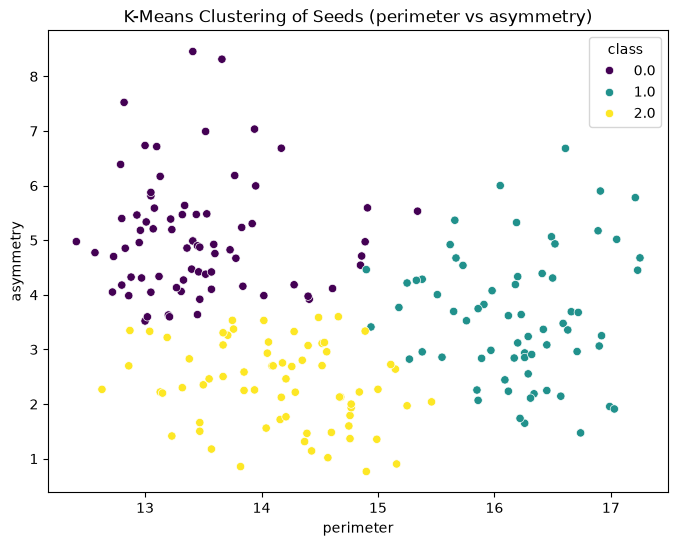

In [10]:
# K Means classes
plt.figure(figsize=(8, 6))
sns.scatterplot(x="perimeter", y="asymmetry", hue="class", data=clusters_df, palette="viridis")
plt.title("K-Means Clustering of Seeds (perimeter vs asymmetry)")
plt.show()

In [11]:
print(df.columns)

Index(['area', 'perimeter', 'compactness', 'length', 'width', 'asymmetry',
       'groove', 'class'],
      dtype='str')


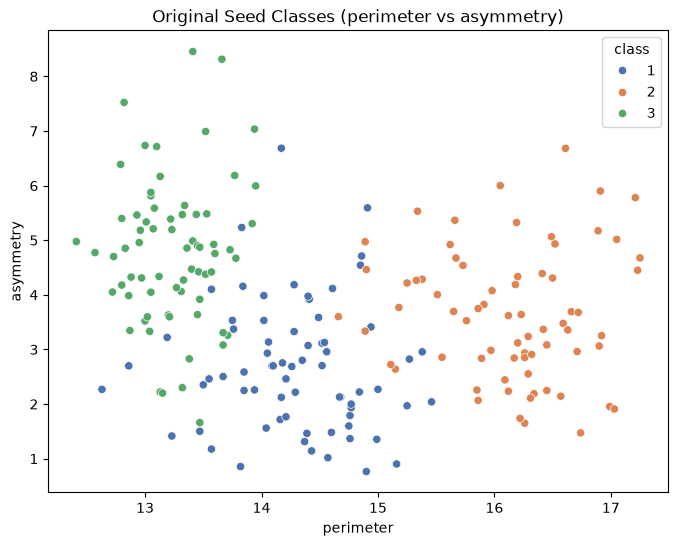

In [12]:
# original dataset

plt.figure(figsize=(8, 6))
sns.scatterplot(x="perimeter", y="asymmetry", hue="class", data=df, palette="deep") 
plt.title("Original Seed Classes (perimeter vs asymmetry)")
plt.show()

## Higher Dimensions


In [18]:
x = df[cols[:-1]].values

In [20]:
# 1. Re-import KMeans to fix the overwritten class
from sklearn.cluster import KMeans

# 2. Fit the model and store it in a new variable name
kmeans_model = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_model.fit(x)

# 3. Get the cluster labels
clusters = kmeans_model.labels_

# 4. Create the dataframe (using the 'clusters' variable, not KMeans.labels_)
cluster_df = pd.DataFrame(np.hstack((x, clusters.reshape(-1, 1))), columns=df.columns)

# 5. Print the first few rows to verify
cluster_df.head()

,area,perimeter,compactness,length,width,asymmetry,groove,class
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,2.0
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,2.0
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,2.0
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,2.0
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,2.0


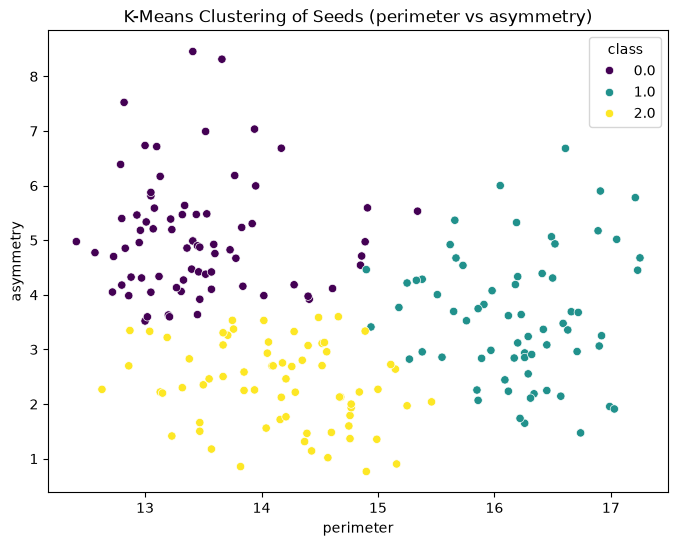

In [21]:
# K Means classes
plt.figure(figsize=(8, 6))
sns.scatterplot(x="perimeter", y="asymmetry", hue="class", data=clusters_df, palette="viridis")
plt.title("K-Means Clustering of Seeds (perimeter vs asymmetry)")
plt.show()

In [ ]:
# 1. Reload the dataset fresh
cols = ["area", "perimeter", "compactness", "length", "width", "asymmetery", "groove", "class"]
df = pd.read_csv("seeds_dataset.txt", sep='\s+', names=cols)

# 2. Convert 'class' to a string so Seaborn treats it as categorical (not continuous)
df['class'] = df['class'].astype(str)

# 3. Plot
plt.figure(figsize=(8, 6))
sns.scatterplot(x="perimeter", y="asymmetery", hue='class', data=df, palette="deep")
plt.title("Original Seed Classes")
plt.show()

<>:3: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:3: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
/var/folders/lg/sczlvrbj0p160b6h4_hgrr2r0000gn/T/ipykernel_6635/1711208364.py:3: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  df = pd.read_csv("seeds_dataset.txt", sep='\s+', names=cols)


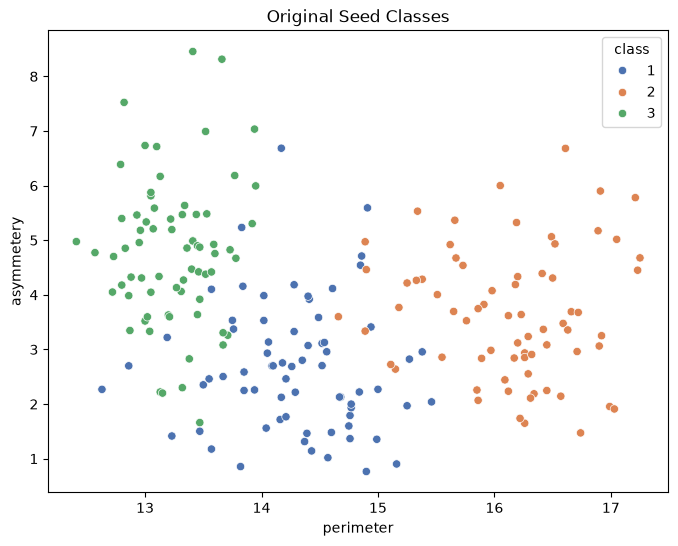

In [30]:
# 1. Reload the dataset fresh
cols = ["area", "perimeter", "compactness", "length", "width", "asymmetery", "groove", "class"]
df = pd.read_csv("seeds_dataset.txt", sep='\s+', names=cols)

# 2. Convert 'class' to string so Seaborn treats it as categorical (prevents further errors)
df['class'] = df['class'].astype(str)

# 3. Plot
plt.figure(figsize=(8, 6))
sns.scatterplot(x="perimeter", y="asymmetery", hue='class', data=df, palette="deep")
plt.title("Original Seed Classes")
plt.show()

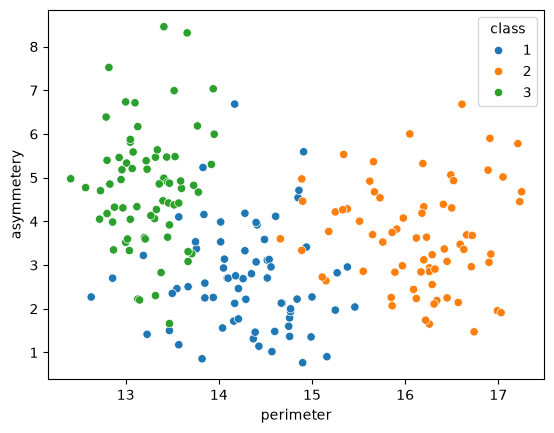

In [31]:
# Original classes
sns.scatterplot(x="perimeter", y="asymmetery", hue='class', data=df)
plt.show()

# PCA

In [32]:
from sklearn.decomposition import PCA

In [33]:
pca = PCA(n_components=2)
transformed_x = pca.fit_transform(x)

In [34]:
x.shape

(210, 7)

In [35]:
transformed_x.shape

(210, 2)

In [36]:
transformed_x[:5]

array([[ 0.66344838, -1.41732098],
       [ 0.31566651, -2.68922915],
       [-0.6604993 , -1.13150635],
       [-1.0552759 , -1.62119002],
       [ 1.61999921, -2.18338442]])

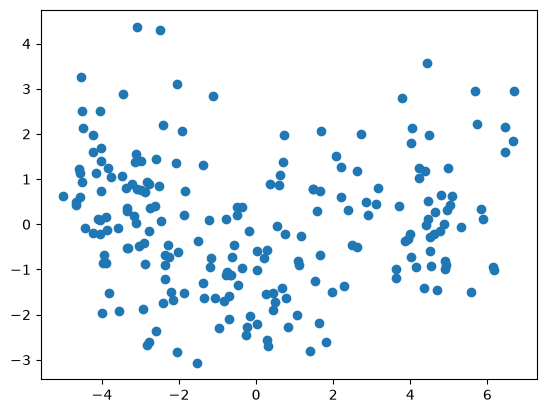

In [38]:
plt.scatter(transformed_x[:,0], transformed_x[:,1] )

In [45]:
kmeans_pca_df = pd.DataFrame(
    np.hstack((transformed_x, clusters.reshape(-1, 1))), 
    columns=["pca1", "pca2", "class"]
)

In [47]:
truth_pca_df = pd.DataFrame(
    np.hstack((transformed_x, df["class"].values.reshape(-1, 1))), 
    columns=["pca1", "pca2", "class"]
)

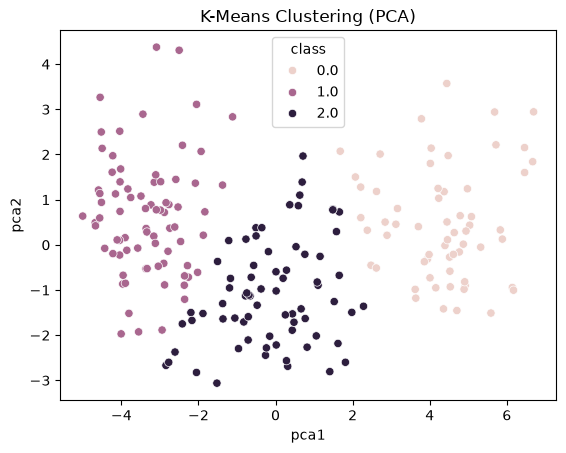

In [48]:
# K Means classes
sns.scatterplot(x='pca1', y='pca2', hue='class', data=kmeans_pca_df)
plt.title("K-Means Clustering (PCA)")
plt.show()

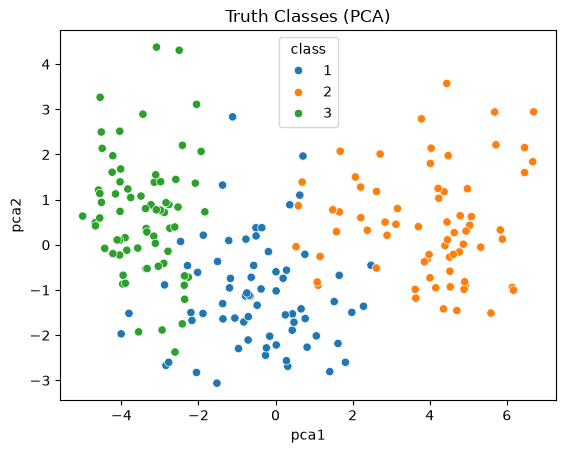

In [50]:
# Truth classes
sns.scatterplot(x='pca1', y='pca2', hue='class', data=truth_pca_df)
plt.title("Truth Classes (PCA)")
plt.show()